In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import ensemble
from sklearn.inspection import permutation_importance
import lightgbm as lgb
import shap
import re

In [ ]:
# Remove pandas display limits
# pd.set_option("display.max_rows", 50)
# pd.set_option("display.max_columns", None)
# pd.set_option("display.max_colwidth", None)
# pd.set_option("display.width", None)

In [2]:
CAPACITY = 140
T_POWER = 120

## Modelling

In [3]:
df_combined = pd.read_csv('data/prepared/df_combined_cleaned.csv', index_col=0)


In [4]:
df_combined.head()

,HEATID,16A,25A,25A1,26A,3A,3ACh,3B23,AShM 75,Aluminum briquet,Anthracite,Artificial graphite 0.1-2.5 mm,B11,B68,Briquet BMK-60,Briquets 6A,CCM 03-10mm,CCM 30-60 mm,Coke 10-30 mm,Dolomite,FGM material,FMN 78 GOST4755-91 class 4,FOMI,FOMI B2,FeCr 850A,FeCr025,FeSi 45,FeSi65-4,Ferrous scrap 6A,Flux FIM,Flux FM-2-1,High-carbon ferrochromium,Hot briquet iron,In-house produced lime,Iron scrap,KRS-65,KRS-65 briquets,KShU 75,Ladle scrap,Lime,"Lime, grade 2",Liquid scrap,Magma,Magma-P,Magnesite brick scrap,MnSi17A,Mo material briquet,Mo pellets,SIMP-RM,Scrap 3B22,Scrap B23,Scrap G/B 25A,Scrap G/B 25AS,Secondary aluminum AV 87,Separation scrap,Separation waste 3A,Shram 75,Steel scrap G/B 25A,Steelmaking iron,Vanadium alloy,Scrap,OBM,Scrap_ratio,TEMP,O2_AMOUNT,GAS_AMOUNT,power_on,power_off,MW,stat_MW,Calc_tap_mass
1,5F0003,0.0,0.0,0.0,0.0,108033.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,511.0,0.0,0.0,0.0,0.0,831.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6067.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,822.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15320.0,0.0,108033.0,15320.0,0.875804,1653.0,3469.0,1117.0,33.50,5.50,48.625,359.657777,108.864887
7,5F0009,0.0,0.0,0.0,0.0,128028.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1806.0,0.0,0.0,0.0,0.0,526.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3233.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,522.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128028.0,0.0,1.000000,1654.0,3439.0,876.0,32.50,5.50,46.125,343.969809,114.051762
8,5F0011,0.0,0.0,0.0,0.0,128687.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1505.0,0.0,0.0,0.0,0.0,531.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5968.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,518.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,128687.0,0.0,1.000000,1678.0,3820.0,951.0,37.32,18.68,49.875,379.573669,113.791425
9,5F0013,0.0,0.0,0.0,0.0,127536.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1507.0,0.0,0.0,0.0,0.0,531.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5967.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,517.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,127536.0,0.0,1.000000,1645.0,3722.0,858.0,35.67,5.33,50.000,364.386880,112.756150
10,5F0015,0.0,0.0,0.0,0.0,126768.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1506.0,0.0,0.0,0.0,0.0,531.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5470.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,517.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,126768.0,0.0,1.000000,1662.0,3738.0,883.0,35.17,3.83,47.750,359.272195,112.220263


In [5]:
df_combined.shape

(18564, 71)

In [6]:
df_full_train, df_test = train_test_split(df_combined, test_size=0.2, random_state=42, shuffle=True)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42, shuffle=True)

In [ ]:
y_full_train = df_full_train['MW'].values
y_train = df_train['MW'].values
y_val = df_val['MW'].values
y_test = df_test['MW'].values

stat_train = df_train['stat_MW'].values * df_train['Calc_tap_mass'] / 1000
stat_val = df_val['stat_MW'].values * df_val['Calc_tap_mass'] / 1000
stat_test = df_test['stat_MW'].values * df_test['Calc_tap_mass'] / 1000

# df_full_train = df_full_train.drop(columns=['HEATID', 'MW', 'stat_MW'])
# df_train = df_train.drop(columns=['HEATID', 'MW', 'stat_MW'])
# df_val = df_val.drop(columns=['HEATID', 'MW', 'stat_MW'])
# df_test = df_test.drop(columns=['HEATID', 'MW', 'stat_MW'])

df_full_train = df_full_train.drop(columns=['HEATID', 'MW'])
df_train = df_train.drop(columns=['HEATID', 'MW'])
df_val = df_val.drop(columns=['HEATID', 'MW'])
df_test = df_test.drop(columns=['HEATID', 'MW'])

## Lin reg

In [8]:
model = make_pipeline(StandardScaler(), RidgeCV(cv=5))

In [9]:
model.fit(df_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](69,)","['16A','25A','25A1',...,'power_off','stat_MW','Calc_tap_mass']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,69
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [10]:
y_pred = model.predict(df_val)

In [11]:
print(f"RMSE: {root_mean_squared_error(y_val, y_pred):.2f}")
print(f"Coefficient of determination: {r2_score(y_val, y_pred):.2f}")

RMSE: 1.41
Coefficient of determination: 0.69


In [12]:
print(f"RMSE: {root_mean_squared_error(y_val, stat_val):.2f}")
print(f"Coefficient of determination: {r2_score(y_val, stat_val):.2f}")

RMSE: 3.93
Coefficient of determination: -1.43


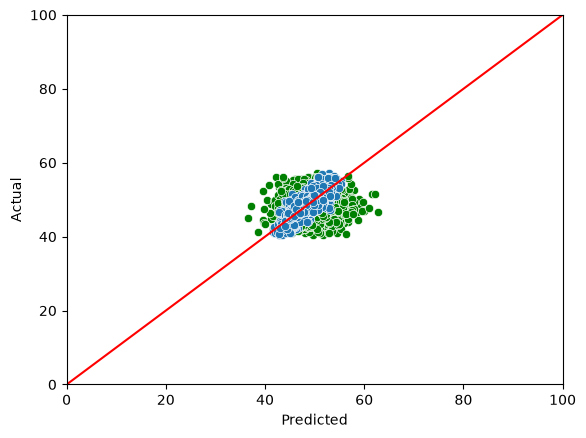

In [ ]:
sns.scatterplot(x=stat_val, y=y_val, c='green')
sns.scatterplot(x=y_pred, y=y_val)
sns.lineplot(x=[0, 80], y=[0, 80], c='red')
plt.xlim([0,80])
plt.ylim([0,80])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

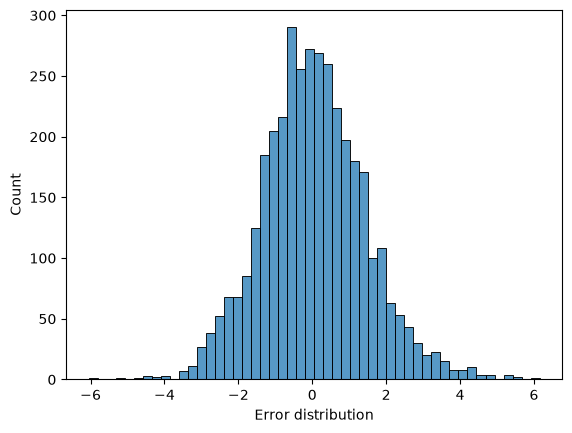

In [14]:
sns.histplot(data=(y_val-y_pred), bins=50)
plt.xlabel('Error distribution')
plt.show()

In [15]:
print(f"Errors mean: {(y_val-y_pred).mean():.3f}")

Errors mean: 0.048


In [16]:
df_coef = pd.DataFrame()
df_coef['coef'] = model.steps[1][1].coef_
df_coef['coef_abs'] = df_coef['coef'].abs()
df_coef['feature'] = df_val.columns

In [17]:
df_coef.sort_values(by='coef_abs', ascending=False)[:15]

,coef,coef_abs,feature
65,1.399813,1.399813,power_on
61,-1.058153,1.058153,Scrap_ratio
59,0.518260,0.518260,Scrap
38,0.497835,0.497835,Lime
68,0.354070,0.354070,Calc_tap_mass
60,-0.330146,0.330146,OBM
57,-0.306077,0.306077,Steelmaking iron
2,0.303064,0.303064,25A1
64,-0.261867,0.261867,GAS_AMOUNT
62,-0.177510,0.177510,TEMP


## Boosting

In [18]:
params = {
    "n_estimators": 500,
    "max_depth": 10,
    "min_samples_split": 5,
    "learning_rate": 0.01,
    "loss": "squared_error",
}

In [19]:
reg = ensemble.GradientBoostingRegressor(**params)
reg.fit(df_train, y_train)

y_pred_b = reg.predict(df_val)

print(f"RMSE: {root_mean_squared_error(y_val, y_pred_b):.2f}")
print(f"Coefficient of determination: {r2_score(y_val, y_pred_b):.2f}")

RMSE: 1.30
Coefficient of determination: 0.74


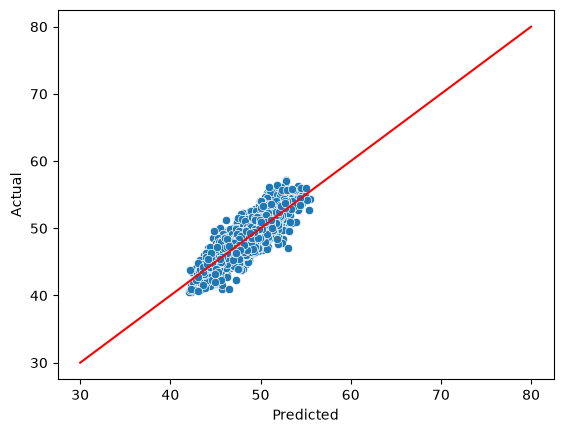

In [20]:
sns.scatterplot(x=y_pred_b, y=y_val)
sns.lineplot(x=[30, 80], y=[30,80], c='red')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

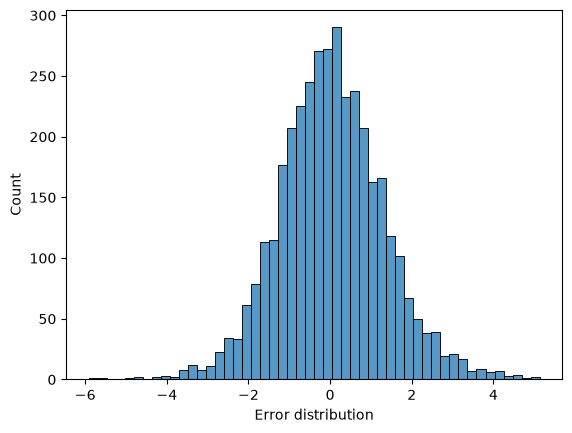

In [21]:
sns.histplot(data=(y_val-y_pred_b), bins=50)
plt.xlabel('Error distribution')
plt.show()

In [22]:
print(f"Errors mean: {(y_val-y_pred_b).mean():.3f}")
print(f"Errors median: {np.median(y_val-y_pred_b):.3f}")

Errors mean: 0.040
Errors median: 0.005


## LightGBM

In [24]:
df_train_lgbm = df_train.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '_', x))
df_val_lgbm = df_val.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '_', x))

In [25]:
d_train = lgb.Dataset(df_train_lgbm, label=y_train)
d_val = lgb.Dataset(df_val_lgbm, label=y_val)

In [26]:
# Set parameters for regression
params = {
    'objective': "regression",
    'n_estimators': 1000,
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': -1,
    'min_child_samples': 30,
    'subsample': 0.8,
    'subsample_freq': 1,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0,
    'random_state': 42,
    'verbosity': -1
}

# Train the model
num_round = 100
reg = lgb.train(params, d_train, num_round, valid_sets=[d_val])

# Predict on the test set
y_pred_lgbm = reg.predict(df_val)

# Calculate RMSE
print(f"RMSE: {root_mean_squared_error(y_val, y_pred_lgbm):.2f}")
print(f"Coefficient of determination: {r2_score(y_val, y_pred_lgbm):.2f}")

RMSE: 1.23
Coefficient of determination: 0.76


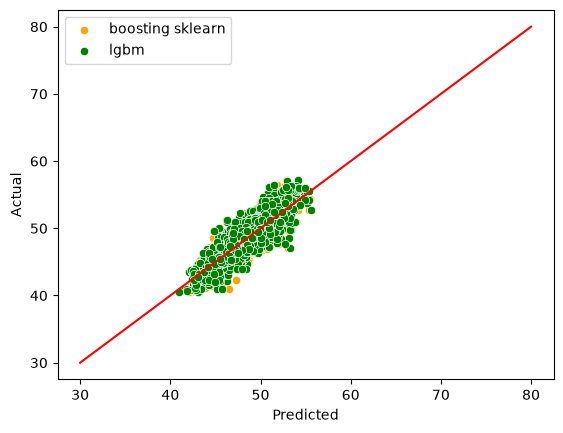

In [27]:
sns.scatterplot(x=y_pred_b, y=y_val, c='orange', label="boosting sklearn")
sns.scatterplot(x=y_pred_lgbm, y=y_val, c='green', label="lgbm")

sns.lineplot(x=[30, 80], y=[30,80], c='red')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [28]:
explainer = shap.TreeExplainer(reg)
shap_values = explainer(df_full_train)

In [29]:
shap.initjs()

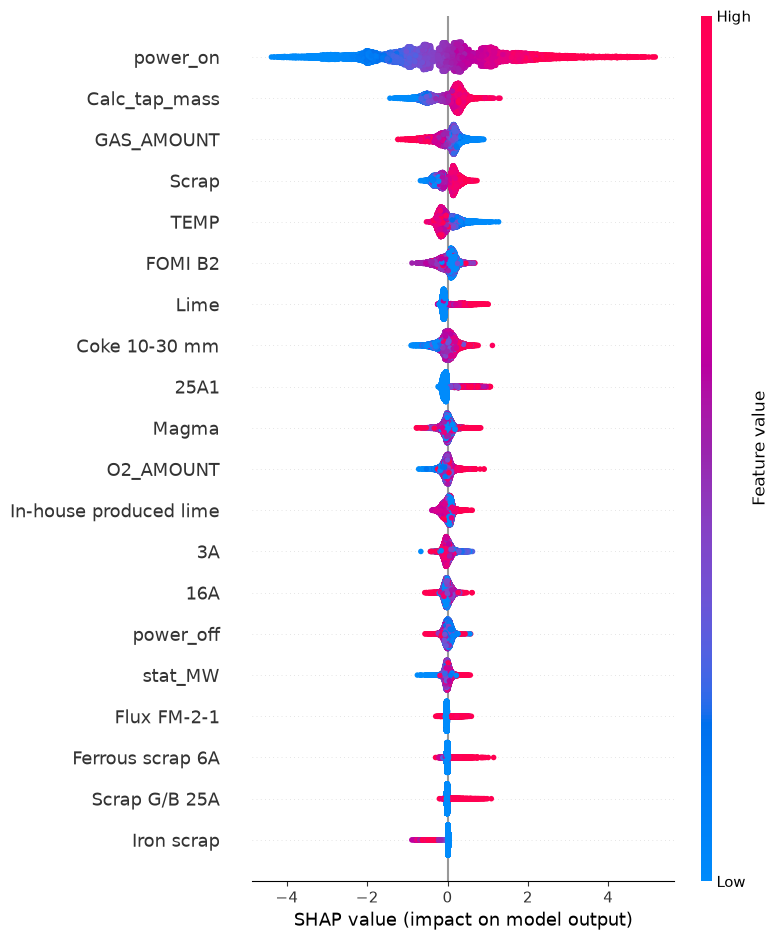

In [30]:
shap.summary_plot(shap_values, df_full_train)

In [33]:
shap.force_plot(explainer.expected_value, shap_values.values[100, :], df_full_train.iloc[100, :])

In [34]:
shap.force_plot(explainer.expected_value, shap_values.values[:1000, :], df_full_train.iloc[:1000, :])